=== ESCENARIO BASE (Modo Guerra $4,600/mes) ===
 Mes  Cuotas_Meses  Liverpool_Rev  Joy_Rev  BBVA_Rev  Deuda_Total
   1       3695.22        1460.76  9009.27   9941.48     39990.81
   2       3469.55        1256.78  8793.46  10437.10     36597.10
   3       3220.22        1039.40  8582.82  10693.07     33204.81
   4       2626.68         766.61  8377.23  10393.18     29799.86
   5       1922.85           0.00  7905.82  10101.70     26347.52
   6       1668.00           0.00  6309.21   9818.40     22799.60
   7       1668.00           0.00  4591.39   9543.04     19138.43
   8       1668.00           0.00  2745.65   9275.40     15357.05
   9       1668.00           0.00   764.85   9015.27     11448.12
  10       1668.00           0.00     0.00   7403.83      7403.83
  11          0.00           0.00     0.00   3221.95      3221.95
  12          0.00           0.00     0.00      0.00         0.00

Meses a deuda $0 (Base): 12 | Intereses rev: $10,605.15
Meses a deuda $0 (Enero libre): 11 | 

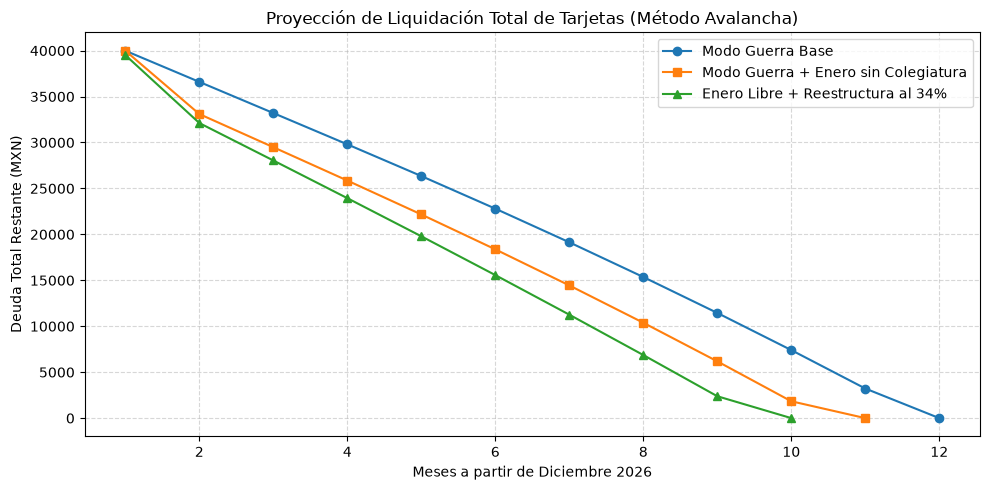

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# ==============================================================================
# 1. CONFIGURACIÓN DE ESCENARIO (MODIFICA AQUÍ TUS SUPUESTOS)
# ==============================================================================
INGRESO_MENSUAL = 9400.0      # $5,000 becario + $4,400 restaurante (promedio)
GASTO_SUPERVIVENCIA = 1300.0  # Transporte + comedor $24 + básicos
COLEGIATURA_MENSUAL = 3500.0  # Ajusta aquí si cambia el próximo semestre
MESES_SIN_COLEGIATURA = [2]   # Ej: Mes 2 = Enero 2027 sin mensualidad (vacío [] si sí pagas)
IVA = 0.16

# Calendario de cuotas fijas a meses (MSI y Diferido Oro) a partir de Mes 1 = Dic 2026
# Formato: (nombre, mensualidad, meses_restantes_desde_dic_2026)
PLANES_MESES = [
    ("Oro_Diferido_34pct", 1668.00, 10),  # Pagos 3 a 12 (termina Sep 2027)
    ("Oro_Amazon_MSI",      225.67,  1),  # Pago 3 de 3 (termina Dic 2026)
    ("BBVA_Amazon_MSI",     204.00,  4),  # Pagos 3 a 6 (termina Mar 2027)
    ("BBVA_Anualidad_MSI",  249.33,  2),  # Pagos 2 a 3 (termina Ene 2027)
    ("Liv_16MSI",           593.54,  3),  # Pagos 14 a 16 (termina Feb 2027)
    ("Liv_6MSI_Oct",        499.83,  4),  # Pagos 3 a 6 (termina Mar 2027)
    ("Liv_6MSI_Videoj",     254.85,  5),  # Pagos 2 a 6 (termina Abr 2027)
]

def simular_avalancha(
    ingreso=INGRESO_MENSUAL,
    supervivencia=GASTO_SUPERVIVENCIA,
    colegiatura=COLEGIATURA_MENSUAL,
    meses_sin_colegiatura=None,
    tasa_joy=0.6302,
    tasa_bbva=0.5842,
    extra_mensual=0.0,
    max_meses=36
):
    if meses_sin_colegiatura is None:
        meses_sin_colegiatura = []

    # Saldos revolventes iniciales (después del pago de $1,200 hoy a Joy)
    # Nota: BBVA revolvente descuenta los $453.33 de cuotas del periodo ya modeladas aparte
    deudas = {
        "Liverpool_Rev": {"saldo": 1652.16, "tasa": 0.6800, "min_pct": 0.10},
        "Joy_Rev":       {"saldo": 9062.00, "tasa": tasa_joy, "min_pct": 0.08},
        "BBVA_Rev":      {"saldo": 9410.07, "tasa": tasa_bbva, "min_pct": 0.08},
    }

    historial = []
    intereses_acumulados = 0.0

    for mes in range(1, max_meses + 1):
        # 1. Calcular flujo disponible para deudas este mes
        coleg_mes = 0.0 if mes in meses_sin_colegiatura else colegiatura
        presupuesto_deuda = ingreso + extra_mensual - supervivencia - coleg_mes

        # 2. Restar cuotas fijas de MSI / Diferido activas en este mes
        cuotas_fijas = sum(monto for _, monto, duracion in PLANES_MESES if mes <= duracion)
        saldo_meses_restante = sum(
            monto * max(0, duracion - mes) for _, monto, duracion in PLANES_MESES
        )

        # 3. Generar intereses + IVA en saldos revolventes vivos
        interes_mes = 0.0
        for nombre, d in deudas.items():
            if d["saldo"] > 0.01:
                int_mensual = d["saldo"] * (d["tasa"] / 12.0) * (1 + IVA)
                d["saldo"] += int_mensual
                interes_mes += int_mensual
        intereses_acumulados += interes_mes

        disponible_rev = max(0.0, presupuesto_deuda - cuotas_fijas)

        # 4. Pagar mínimos primero en revolventes
        orden_avalancha = sorted(deudas.keys(), key=lambda k: deudas[k]["tasa"], reverse=True)
        for nombre in orden_avalancha:
            d = deudas[nombre]
            if d["saldo"] > 0 and disponible_rev > 0:
                pago_min = min(d["saldo"], max(300.0, d["saldo"] * d["min_pct"]))
                pago = min(pago_min, disponible_rev)
                d["saldo"] -= pago
                disponible_rev -= pago

        # 5. Inyectar TODO el excedente a la tasa más alta (Avalancha)
        for nombre in orden_avalancha:
            d = deudas[nombre]
            if d["saldo"] > 0 and disponible_rev > 0:
                pago = min(d["saldo"], disponible_rev)
                d["saldo"] -= pago
                disponible_rev -= pago

        total_rev = sum(d["saldo"] for d in deudas.values())
        total_deuda = total_rev + saldo_meses_restante

        historial.append({
            "Mes": mes,
            "Presupuesto_Deuda": round(presupuesto_deuda, 2),
            "Cuotas_Meses": round(cuotas_fijas, 2),
            "Liverpool_Rev": round(deudas["Liverpool_Rev"]["saldo"], 2),
            "Joy_Rev": round(deudas["Joy_Rev"]["saldo"], 2),
            "BBVA_Rev": round(deudas["BBVA_Rev"]["saldo"], 2),
            "Saldo_Planes_Meses": round(saldo_meses_restante, 2),
            "Deuda_Total": round(total_deuda, 2),
            "Interes_Mes": round(interes_mes, 2),
            "Interes_Acum": round(intereses_acumulados, 2),
        })

        if total_deuda <= 1.0:
            break

    return pd.DataFrame(historial)

# ==============================================================================
# 2. CORRER Y COMPARAR ESCENARIOS
# ==============================================================================
df_base = simular_avalancha(meses_sin_colegiatura=[])
df_enero_libre = simular_avalancha(meses_sin_colegiatura=[2])  # Enero sin colegiatura
df_reestructura = simular_avalancha(
    meses_sin_colegiatura=[2], tasa_joy=0.34, tasa_bbva=0.34   # Reestructura a ~34%
)

print("=== ESCENARIO BASE (Modo Guerra $4,600/mes) ===")
print(df_base[["Mes", "Cuotas_Meses", "Liverpool_Rev", "Joy_Rev", "BBVA_Rev", "Deuda_Total"]].to_string(index=False))
print(f"\nMeses a deuda $0 (Base): {len(df_base)} | Intereses rev: ${df_base['Interes_Acum'].iloc[-1]:,.2f}")
print(f"Meses a deuda $0 (Enero libre): {len(df_enero_libre)} | Intereses rev: ${df_enero_libre['Interes_Acum'].iloc[-1]:,.2f}")
print(f"Meses a deuda $0 (Enero libre + Tasa 34%): {len(df_reestructura)} | Intereses rev: ${df_reestructura['Interes_Acum'].iloc[-1]:,.2f}")

# Exportar tabla detallada para llevar seguimiento en Excel/Obsidian
df_enero_libre.to_csv("calendario_salida_deudas.csv", index=False)

# ==============================================================================
# 3. GRÁFICA COMPARATIVA
# ==============================================================================
plt.figure(figsize=(10, 5))
plt.plot(df_base["Mes"], df_base["Deuda_Total"], marker="o", label="Modo Guerra Base")
plt.plot(df_enero_libre["Mes"], df_enero_libre["Deuda_Total"], marker="s", label="Modo Guerra + Enero sin Colegiatura")
plt.plot(df_reestructura["Mes"], df_reestructura["Deuda_Total"], marker="^", label="Enero Libre + Reestructura al 34%")

plt.title("Proyección de Liquidación Total de Tarjetas (Método Avalancha)")
plt.xlabel("Meses a partir de Diciembre 2026")
plt.ylabel("Deuda Total Restante (MXN)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()